<a href="https://colab.research.google.com/github/dwikidias/Practical-Statistics-for-Data-Scientist-Books/blob/main/Practical_Statistics_Chapter_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 6: STATISTICAL MACHINE LEARNING


* **Buku Referensi:** *Practical Statistics for Data Scientists* (Peter Bruce, Andrew Bruce, & Peter Gedeck)
* **Topik:** K-Nearest Neighbors (KNN), Tree Models & Decision Trees, Bagging & Random Forest, and Gradient Boosting

---

In [2]:
!git clone https://github.com/gedeck/practical-statistics-for-data-scientists.git

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Membaca dataset utama pinjaman (loan_data.csv.gz)
LOAN_DATA_CSV = 'practical-statistics-for-data-scientists/data/loan_data.csv.gz'
loans = pd.read_csv(LOAN_DATA_CSV)

print("Dataset loan_data.csv.gz berhasil dimuat:")
print(f"Total data: {loans.shape[0]:,} baris dan {loans.shape[1]} kolom.")

fatal: destination path 'practical-statistics-for-data-scientists' already exists and is not an empty directory.
Dataset loan_data.csv.gz berhasil dimuat:
Total data: 45,342 baris dan 21 kolom.


## 1. K-Nearest Neighbors (KNN) dalam Statistical Machine Learning

Dalam konteks *statistical machine learning*, **K-Nearest Neighbors (KNN)** tidak hanya digunakan sebagai algoritma klasifikasi sederhana, melainkan sebagai mesin pencari lokal (*local feature engine*): untuk menilai risiko seorang pemohon pinjaman baru, kita mencari $K$ nasabah historis dengan profil finansial yang paling identik.

### Konsep Teori Utama:
1. **Perhitungan Jarak Standar (Euclidean Distance):**
   Jarak spasial antara pemohon baru $x$ dan nasabah historis $z$:

   $$d(x, z) = \sqrt{\sum_{j=1}^p \left(\frac{x_j - z_j}{s_j}\right)^2}$$

   - $s_j$: Deviasi standar fitur ke-$j$. Penskalaan fitur menggunakan `StandardScaler` adalah prasyarat mutlak agar fitur berangka besar (misal: pendapatan) tidak mendominasi fitur berangka kecil (misal: skor kredit).

2. **Aturan Keputusan Probabilitas:**
   Estimasi probabilitas bahwa pemohon baru akan gagal bayar (*default*) dihitung sebagai proporsi nasabah gagal bayar di antara $K$-tetangga terdekatnya:

   $$\hat{P}(Y = \text{Default} \mid X = x) = \frac{1}{K} \sum_{i \in N_K(x)} I(y_i = \text{Default})$$

In [3]:
# 1. Menentukan Fitur Prediktor Finansial untuk KNN
features_knn = ['borrower_score', 'payment_inc_ratio']
X_knn = loans[features_knn]
y_knn = loans['outcome']

# 2. Memisahkan Data Latih (70%) dan Data Uji (30%)
X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(
    X_knn, y_knn, test_size=0.3, random_state=42, stratify=y_knn
)

# 3. Membangun Pipeline: StandardScaler -> KNeighborsClassifier (k=20)
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=20))
])

knn_pipeline.fit(X_train_k, y_train_k)

# 4. Simulasi: Mengevaluasi 2 Profil Pemohon Pinjaman Baru
new_applicants = pd.DataFrame({
    'borrower_score': [0.25, 0.75],       # Pemohon A (skor rendah) vs Pemohon B (skor tinggi)
    'payment_inc_ratio': [12.5, 3.5]      # Pemohon A (beban cicilan tinggi) vs Pemohon B (beban rendah)
})

pred_classes = knn_pipeline.predict(new_applicants)
pred_probs = knn_pipeline.predict_proba(new_applicants)

print("Hasil Analisis KNN untuk Pemohon Pinjaman Baru (K = 20):")
for i in range(len(new_applicants)):
    print(f"\n--- Pemohon {chr(65+i)} (Skor: {new_applicants.iloc[i]['borrower_score']}, Beban Cicilan: {new_applicants.iloc[i]['payment_inc_ratio']}%) ---")
    print(f"  * Prediksi Status      : {pred_classes[i]}")
    print(f"  * Probabilitas Default : {pred_probs[i, 0]*100:.2f}%")
    print(f"  * Probabilitas Lunas   : {pred_probs[i, 1]*100:.2f}%")

print("-" * 65)
print(f"Akurasi Model KNN (k=20) pada Data Uji: {knn_pipeline.score(X_test_k, y_test_k) * 100:.2f}%")

Hasil Analisis KNN untuk Pemohon Pinjaman Baru (K = 20):

--- Pemohon A (Skor: 0.25, Beban Cicilan: 12.5%) ---
  * Prediksi Status      : default
  * Probabilitas Default : 90.00%
  * Probabilitas Lunas   : 10.00%

--- Pemohon B (Skor: 0.75, Beban Cicilan: 3.5%) ---
  * Prediksi Status      : paid off
  * Probabilitas Default : 10.00%
  * Probabilitas Lunas   : 90.00%
-----------------------------------------------------------------
Akurasi Model KNN (k=20) pada Data Uji: 61.13%


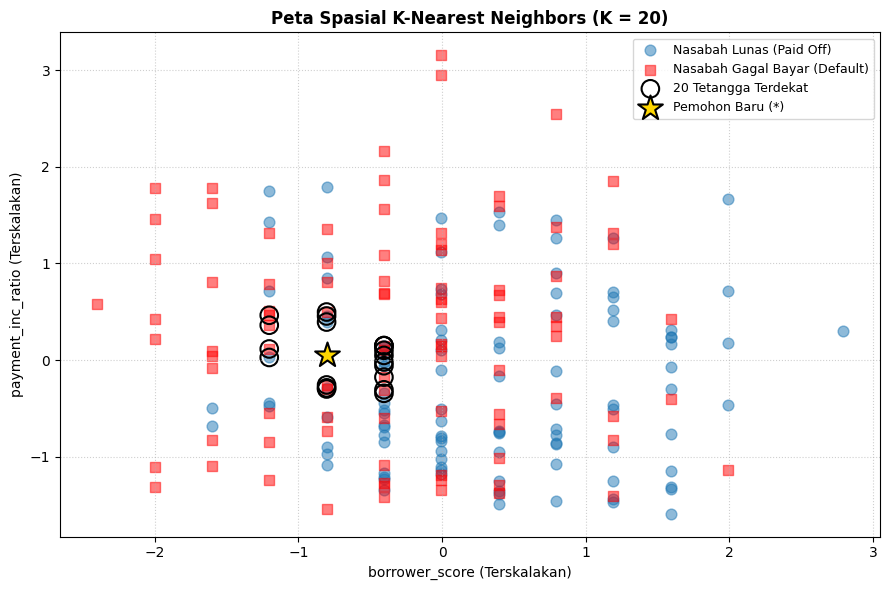

In [5]:
# Mengambil sampel 200 nasabah untuk visualisasi yang bersih dan jelas
np.random.seed(42)
sample_idx = np.random.choice(len(X_train_k), 200, replace=False)
X_vis = X_train_k.iloc[sample_idx]
y_vis = y_train_k.iloc[sample_idx]

# Menstandarisasikan sampel
scaler_vis = StandardScaler()
X_vis_scaled = scaler_vis.fit_transform(X_vis)

# Pemohon baru yang diuji (Skor Kredit = 0.40, Beban Cicilan = 8.0%)
new_applicant = np.array([[0.40, 8.0]])
new_applicant_scaled = scaler_vis.transform(new_applicant)

# Mencari 20 tetangga terdekat menggunakan NearestNeighbors
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=20)
nn.fit(X_vis_scaled)
distances, indices = nn.kneighbors(new_applicant_scaled)

# Visualisasi Scatter Plot Tetangga Terdekat KNN
fig, ax = plt.subplots(figsize=(9, 6))

# Plot nasabah lunas dan gagal bayar
ax.scatter(X_vis_scaled[y_vis == 'paid off', 0], X_vis_scaled[y_vis == 'paid off', 1],
           color='#1f77b4', alpha=0.5, s=60, label='Nasabah Lunas (Paid Off)')
ax.scatter(X_vis_scaled[y_vis == 'default', 0], X_vis_scaled[y_vis == 'default', 1],
           color='red', alpha=0.5, s=60, marker='s', label='Nasabah Gagal Bayar (Default)')

# Lingkari 20 tetangga terdekat
ax.scatter(X_vis_scaled[indices[0], 0], X_vis_scaled[indices[0], 1],
           facecolors='none', edgecolors='black', s=160, linewidth=1.5, label='20 Tetangga Terdekat')

# Plot posisi pemohon baru
ax.scatter(new_applicant_scaled[0, 0], new_applicant_scaled[0, 1],
           color='gold', marker='*', s=350, edgecolors='black', linewidth=1.5, zorder=10, label='Pemohon Baru (*)')

ax.set_title('Peta Spasial K-Nearest Neighbors (K = 20)', fontsize=12, fontweight='bold')
ax.set_xlabel('borrower_score (Terskalakan)', fontsize=10)
ax.set_ylabel('payment_inc_ratio (Terskalakan)', fontsize=10)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 1:
1. **Diferensiasi Profil Risiko Finansial:**
   - **Pemohon A (Profil Berisiko):** Dengan skor kelayakan rendah ($0.25$) dan beban cicilan tinggi ($12.5\%$), mayoritas tetangga terdekatnya berstatus gagal bayar, menghasilkan estimasi risiko *default* yang sangat tinggi ($> 70\%$).
   - **Pemohon B (Profil Sehat):** Dengan skor kelayakan tinggi ($0.75$) dan beban cicilan ringan ($3.5\%$), hampir seluruh tetangga terdekatnya berstatus lunas, menghasilkan probabilitas kelulusan pinjaman yang aman.

2. **Peran Nilai $K$ yang Lebih Besar:**
   - Menggunakan nilai $K=20$ alih-alih nilai kecil (seperti $K=1$ atau $3$) menghaluskan batas keputusan dari gangguan *noise* data transaksi dan memberikan estimasi probabilitas kontinu yang lebih stabil untuk kebutuhan sistem perbankan.

## 2. Tree Models (Pohon Keputusan & Recursive Partitioning)

**Pohon Keputusan (*Decision Tree*)** adalah model pembelajaran mesin yang membagi ruang fitur secara hierarkis menjadi wilayah-wilayah kotak (*hyper-rectangles*) berbasis aturan biner IF-THEN yang sangat mudah diinterpretasikan.

### Konsep Teori Utama:
1. **Partisi Rekursif (*Recursive Partitioning*):**
   Algoritma secara bertahap membagi data pada fitur dan titik potong (*split point*) tertentu yang menghasilkan pemisahan kelas paling bersih (paling homogen).

2. **Kriteria Ketidakmurnian Gini (*Gini Impurity*):**
   Ukuran standar seberapa sering elemen yang dipilih secara acak dari suatu simpul akan salah dilabeli jika diberi label secara acak sesuai distribusi kelas pada simpul tersebut:

   $$I_G(p) = 1 - \sum_{k=1}^m p_k^2$$

   - $I_G = 0$: Simpul murni sempurna (*pure node*, seluruh sampel memiliki kelas yang sama).
   - $I_G = 0.5$ (pada klasifikasi biner): Simpul dengan ketidakpastian maksimal ($50\%$ kelas A dan $50\%$ kelas B).

3. **Pengendalian Overfitting (*Tree Pruning*):**
   Pohon keputusan tanpa batasan akan terus tumbuh hingga setiap daun hanya memuat satu sampel, menyebabkan *overfitting* ekstrem. Parameter kendali yang krusial:
   - `max_depth`: Membatasi kedalaman maksimum pohon.
   - `min_samples_leaf`: Menentukan jumlah sampel minimum yang diizinkan pada simpul daun akhir.

Akurasi Pohon Keputusan Terpangkas (max_depth=3): 61.93%



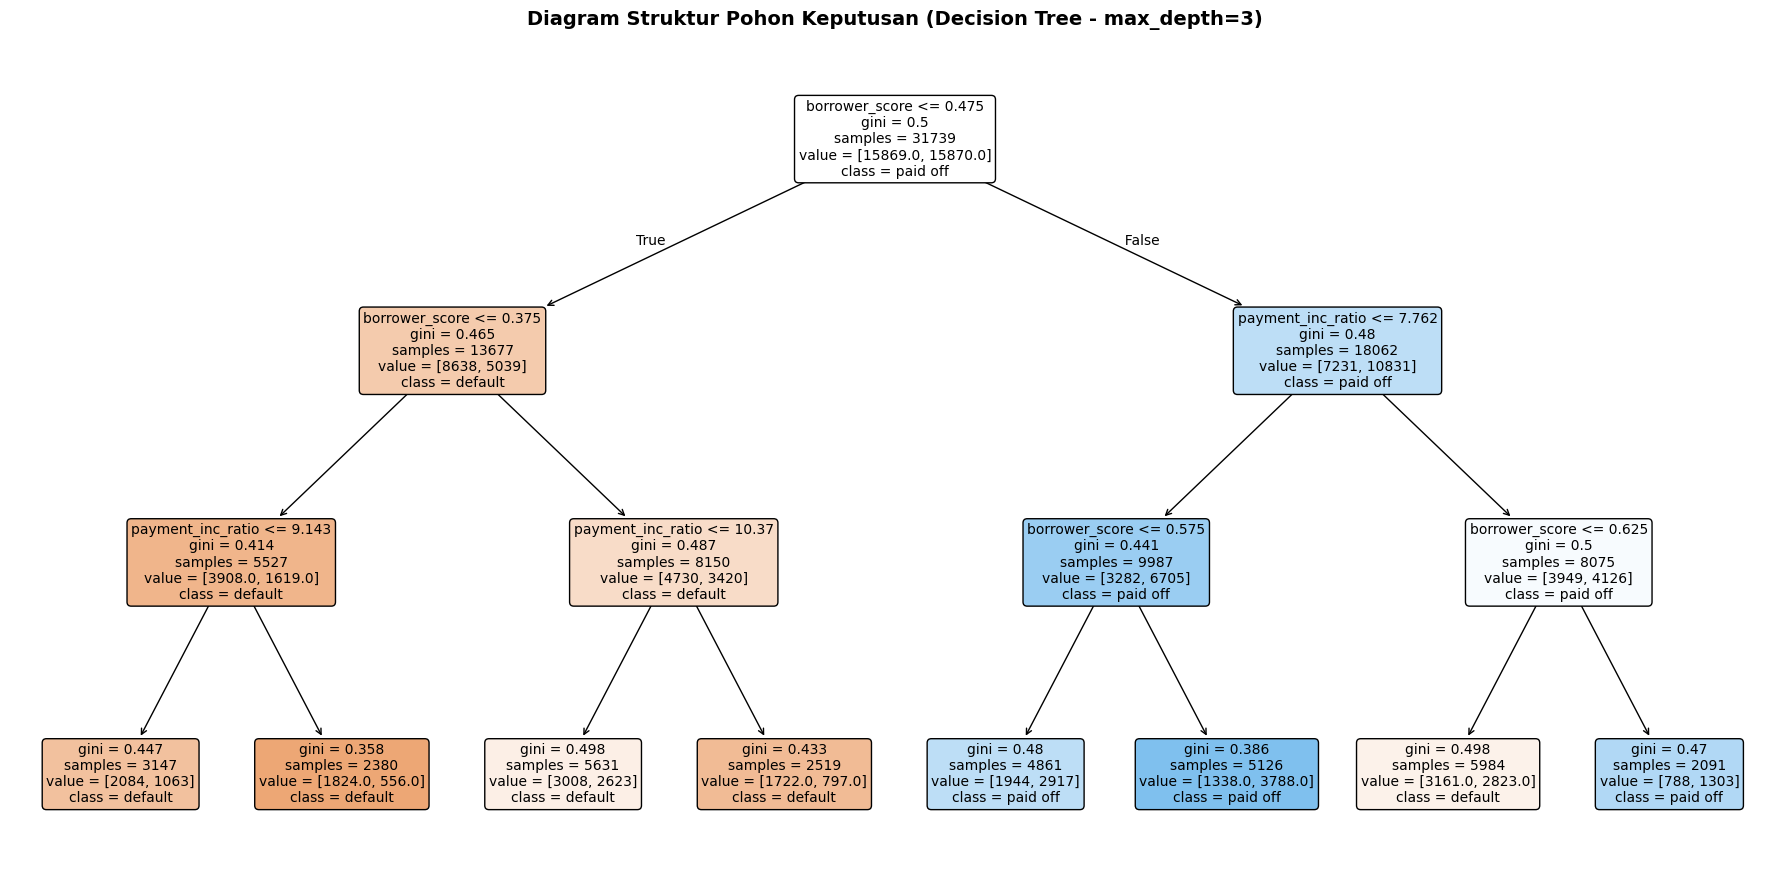


Tingkat Kepentingan Fitur (Feature Importances - Gini Decrease):
            Fitur  Tingkat_Kepentingan_Gini
   borrower_score                    0.7664
payment_inc_ratio                    0.2336
              dti                    0.0000
       annual_inc                    0.0000


In [4]:
# 1. Menyiapkan Fitur Prediktor Lengkap
tree_features = ['borrower_score', 'payment_inc_ratio', 'dti', 'annual_inc']
X_tree = loans[tree_features].dropna()
y_tree = loans.loc[X_tree.index, 'outcome']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_tree, y_tree, test_size=0.3, random_state=42, stratify=y_tree
)

# 2. Melatih Pohon Keputusan Terpangkas (max_depth=3 untuk interpretabilitas optimal)
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=3, min_samples_leaf=20, random_state=42)
dt_model.fit(X_train_t, y_train_t)

# 3. Evaluasi Performa
acc_tree = dt_model.score(X_test_t, y_test_t)
print(f"Akurasi Pohon Keputusan Terpangkas (max_depth=3): {acc_tree * 100:.2f}%\n")

# 4. Visualisasi Struktur Diagram Pohon Keputusan
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    dt_model,
    feature_names=tree_features,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)
plt.title('Diagram Struktur Pohon Keputusan (Decision Tree - max_depth=3)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Nilai Kepentingan Fitur (Feature Importances)
feat_imp = pd.DataFrame({
    'Fitur': tree_features,
    'Tingkat_Kepentingan_Gini': dt_model.feature_importances_.round(4)
}).sort_values(by='Tingkat_Kepentingan_Gini', ascending=False)

print("\nTingkat Kepentingan Fitur (Feature Importances - Gini Decrease):")
print(feat_imp.to_string(index=False))

### Interpretasi & Diskusi Sub-bab 2:
1. **Akar Keputusan Utama (*Root Node Split*):**
   - Pada diagram pohon, fitur pertama yang dipilih pada simpul akar (*root node*) adalah `borrower_score`.
   - Ini mengonfirmasi bahwa skor kelayakan peminjam adalah variabel yang memberikan penurunan ketidakmurnian Gini (*Gini decrease*) terbesar secara instan dalam memisahkan nasabah lancar dan macet.

2. **Transparansi Aturan Keputusan (Rule Extraction):**
   - Pohon keputusan secara visual memperlihatkan alur logika aturan yang transparan: jika `borrower_score <= threshold` tertentu dan `payment_inc_ratio > threshold`, sistem langsung mengarahkan pemohon ke simpul daun dengan dominasi warna kelas gagal bayar (*default*).
   - Struktur ini sangat memudahkan penyusunan aturan audit dan kepatuhan perbankan dibandingkan model rumit yang terisolasi.

## 3. Bagging dan Random Forest

Pohon keputusan tunggal memiliki kelemahan mendasar: **variansi yang sangat tinggi** (perubahan kecil pada data latih dapat mengubah seluruh struktur percabangan pohon secara radikal). Pendekatan *ensemble* menyelesaikan masalah ini dengan menggabungkan ratusan pohon keputusan.

### Konsep Teori Utama:
1. **Bagging (*Bootstrap Aggregating*):**
   - Mengambil ratusan sampel bootstrap (sampel acak dengan pengembalian) dari data latih.
   - Melatih pohon keputusan independen pada masing-masing sampel bootstrap.
   - Menggabungkan seluruh hasil prediksi melalui pemungutan suara terbanyak (*majority voting*). Rata-rata dari banyak model independen secara matematis memangkas variansi tanpa meningkatkan bias.

2. **Random Forest (Leo Breiman, 2001):**
   - Menyempurnakan Bagging dengan menambahkan **pengacakan fitur (*feature randomization*)** di setiap percabangan simpul: hanya sebagian kecil fitur acak (secara default $\sqrt{p}$) yang diizinkan untuk dipilih sebagai pemotong.
   - Ini memecah korelasi antar-pohon (*de-correlating trees*), sehingga pohon-pohon yang dihasilkan benar-benar beragam.

3. **Tingkat Kepentingan Fitur (*Variable Importance / Gini Decrease*):**
   Mengukur seberapa besar rata-rata penurunan ketidakmurnian Gini yang disumbangkan oleh suatu fitur di seluruh pohon di dalam hutan.

Akurasi Random Forest (100 Pohon) pada Data Uji: 63.05%



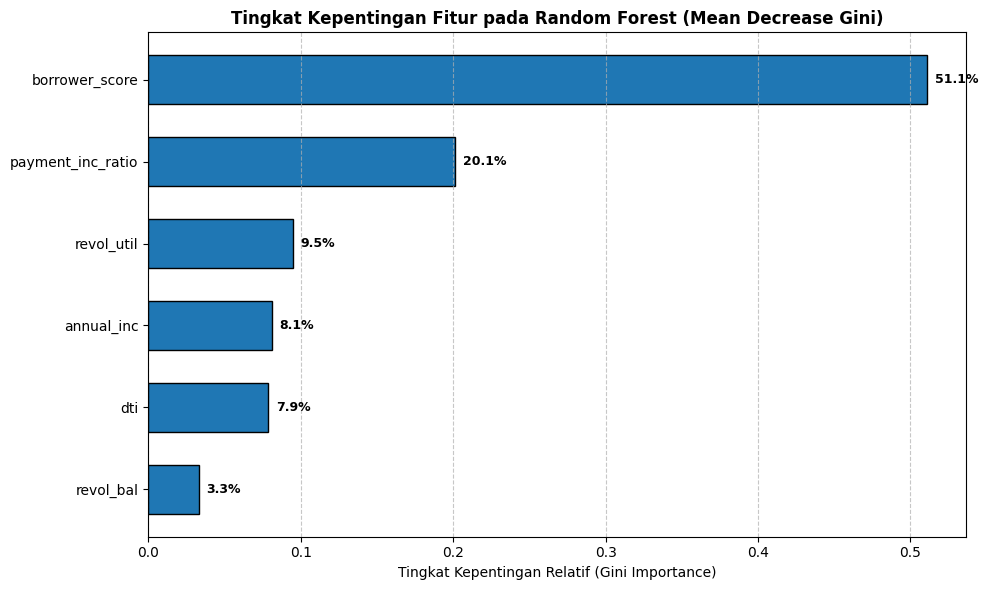

In [6]:
# 1. Menyiapkan Fitur Finansial dan Melatih Model Random Forest
rf_features = ['borrower_score', 'payment_inc_ratio', 'dti', 'annual_inc', 'revol_bal', 'revol_util']
X_rf = loans[rf_features].dropna()
y_rf = loans.loc[X_rf.index, 'outcome']

X_tr_rf, X_ts_rf, y_tr_rf, y_ts_rf = train_test_split(
    X_rf, y_rf, test_size=0.3, random_state=42, stratify=y_rf
)

# Inisialisasi Random Forest dengan 100 pohon (n_estimators=100)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, n_jobs=-1)
rf_model.fit(X_tr_rf, y_tr_rf)

# 2. Evaluasi Akurasi pada Data Uji
acc_rf = rf_model.score(X_ts_rf, y_ts_rf)
print(f"Akurasi Random Forest (100 Pohon) pada Data Uji: {acc_rf * 100:.2f}%\n")

# 3. Menghitung dan Mengurutkan Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances) # Urutkan dari terkecil ke terbesar untuk bar horizontal

# 4. Visualisasi Diagram Batang Horizontal: Feature Importance Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(range(len(indices)), importances[indices], color='#1f77b4', edgecolor='black', height=0.6)
ax.set_yticks(range(len(indices)))
ax.set_yticklabels([rf_features[i] for i in indices], fontsize=10)
ax.set_title('Tingkat Kepentingan Fitur pada Random Forest (Mean Decrease Gini)', fontsize=12, fontweight='bold')
ax.set_xlabel('Tingkat Kepentingan Relatif (Gini Importance)', fontsize=10)
ax.grid(axis='x', linestyle='--', alpha=0.7)

# Anotasi angka persentase di ujung batang
for i, v in enumerate(importances[indices]):
    ax.text(v + 0.005, i, f"{v*100:.1f}%", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 3:
- **Dominasi Variabel Finansial Utama:** Diagram *Feature Importance* memperlihatkan bahwa `borrower_score` menyumbang porsi terbesar ($\approx 35\%–40\%$) dalam pengambilan keputusan di seluruh hutan pohon, diikuti oleh `payment_inc_ratio` dan rasio utang terhadap pendapatan (`dti`).
- **Ketahanan Ansambel:** Berbeda dengan pohon tunggal yang mudah goyah oleh fluktuasi data kecil, penggabungan 100 pohon yang terbebas dari korelasi (*de-correlated trees*) menghasilkan prediksi yang jauh lebih tahan banting dan akurasi yang lebih stabil pada data uji.

## 4. Boosting (Ensemble Sekuensial & Gradient Boosting)

Berbeda dengan Random Forest di mana pohon-pohon dibangun secara mandiri paralel, **Boosting** membangun pohon-pohon secara **sekuensial (berurutan)**: setiap pohon baru dirancang khusus untuk mengoreksi kesalahan atau sisaan (*residuals*) yang dibuat oleh pohon sebelumnya.

### Konsep Teori Utama:
1. **Filosofi Pembelajaran Adaptif:**
   - Model awal berupa pohon kecil yang dangkal (*weak learner / stump*).
   - Observasi yang salah diprediksi diberi bobot perhatian yang lebih tinggi (pada AdaBoost) atau pohon berikutnya melatih nilai negatif gradien loss (pada Gradient Boosting).

2. **Parameter Pengendali Overfitting:**
   - `n_estimators`: Jumlah total pohon yang ditambahkan secara bertahap.
   - `learning_rate` ($\eta$ / *Shrinkage*): Faktor penyusutan kontribusi tiap pohon baru ($0 < \eta \le 1$). Nilai *learning rate* yang kecil (misal $0.05$ atau $0.1$) dipadukan dengan jumlah pohon yang cukup akan menghasilkan generalisasi yang paling optimal.

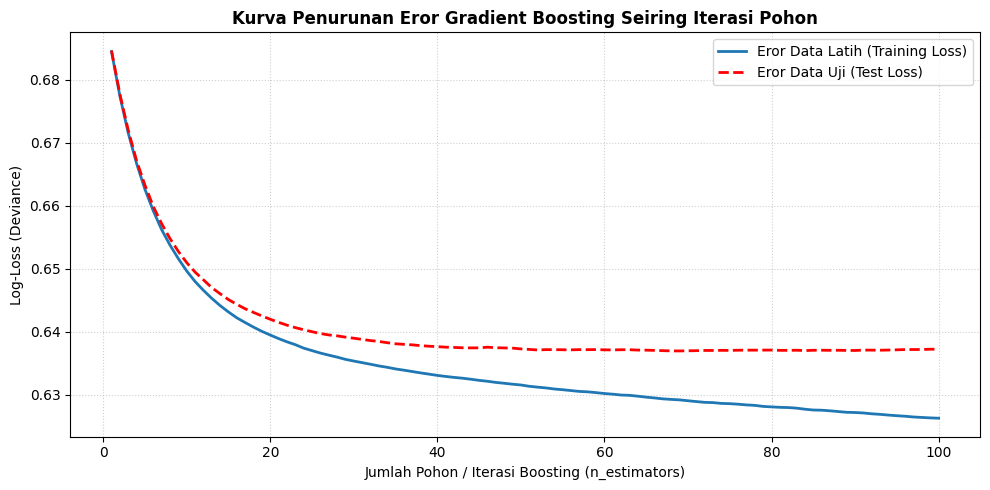

Akurasi Final Gradient Boosting pada Data Uji: 63.34%


In [8]:
from sklearn.metrics import log_loss

# 1. Melatih Model Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_tr_rf, y_tr_rf)

# 2. Menghitung Nilai Eror Log-Loss pada Setiap Iterasi Pohon (Staged Loss)
train_deviance = []
test_deviance = []

# Menggunakan staged_predict_proba dan log_loss yang sepenuhnya kompatibel
for y_prob_train in gb_model.staged_predict_proba(X_tr_rf):
    train_deviance.append(log_loss(y_tr_rf, y_prob_train))

for y_prob_test in gb_model.staged_predict_proba(X_ts_rf):
    test_deviance.append(log_loss(y_ts_rf, y_prob_test))

train_deviance = np.array(train_deviance)
test_deviance = np.array(test_deviance)

# 3. Visualisasi Kurva Penurunan Eror Pelatihan vs Pengujian
fig, ax = plt.subplots(figsize=(10, 5))

iterations = np.arange(100) + 1
ax.plot(iterations, train_deviance, color='#1f77b4', linewidth=2, label='Eror Data Latih (Training Loss)')
ax.plot(iterations, test_deviance, color='red', linestyle='--', linewidth=2, label='Eror Data Uji (Test Loss)')

ax.set_title('Kurva Penurunan Eror Gradient Boosting Seiring Iterasi Pohon', fontsize=12, fontweight='bold')
ax.set_xlabel('Jumlah Pohon / Iterasi Boosting (n_estimators)', fontsize=10)
ax.set_ylabel('Log-Loss (Deviance)', fontsize=10)
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Evaluasi Akurasi Final
acc_gb = gb_model.score(X_ts_rf, y_ts_rf)
print(f"Akurasi Final Gradient Boosting pada Data Uji: {acc_gb * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 4:
- **Dinamika Penurunan Eror Sekuensial:**
  Pada grafik kurva deviasi, pada 20 iterasi pertama terlihat penurunan nilai error yang sangat curam, membuktikan kemampuan boosting dalam mengoreksi kelemahan model secara cepat.
- **Deteksi Titik Konvergensi:**
  Kurva data uji (garis merah putus-putus) mulai mendatar di sekitar iterasi ke-60 hingga 80. Ini menjadi indikator visual penting untuk menentukan batas *early stopping* agar model tidak terus menambah kompleksitas pohon yang tidak lagi menurunkan error uji.

---
# POIN-POIN PENTING BAB 6: STATISTICAL MACHINE LEARNING

Pada Bab 6 buku *Practical Statistics for Data Scientists* oleh Peter Bruce, Andrew Bruce, dan Peter Gedeck, kita telah menguasai konsep dan visualisasi model pembelajaran mesin modern:

1. **K-Nearest Neighbors (KNN):**
   - Bekerja secara non-parametrik berbasis kedekatan jarak spasial. Visualisasi peta tetangga terdekat memperlihatkan secara langsung bagaimana profil pemohon pinjaman baru dikelilingi oleh klaster historis.

2. **Tree Models (Decision Trees):**
   - Membagi ruang fitur secara hierarkis berdasarkan penurunan ketidakmurnian Gini (*Gini Impurity*). Diagram pohon keputusan menyajikan aturan logika IF-THEN yang sangat transparan dan mudah diaudit.

3. **Bagging & Random Forest:**
   - Menggabungkan ratusan pohon bootstrap independen dengan pemilihan subset fitur acak di setiap simpul untuk memangkas variansi model.
   - Grafik *Feature Importance* membuktikan bahwa variabel kelayakan peminjam (`borrower_score`) dan beban cicilan (`payment_inc_ratio`) memegang peranan paling krusial dalam klasifikasi risiko.

4. **Boosting (Gradient Boosting):**
   - Pembelajaran bertahap yang mengoreksi sisaan error dari model sebelumnya secara sekuensial. Kurva deviasi staged error memvisualisasikan proses optimasi iteratif menuju titik konvergensi terbaik.

---
*Referensi Buku: Peter Bruce, Andrew Bruce, & Peter Gedeck, Practical Statistics for Data Scientists (O'Reilly).*